In [1]:
%pip install matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [4]:
df = pd.read_csv('course_lead_scoring_2026_2.csv')

Data preparation
Check if the missing values are presented in the features.
If there are missing values:
For categorical features, replace them with 'NA'
For numerical features, replace with with 0.0

In [10]:
print(df.isnull().sum())

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [6]:
print(df.dtypes)
df.head()

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [7]:
df['lead_source'] = df['lead_source'].fillna('NA')
df['industry'] = df['industry'].fillna('NA')
df['employment_status'] = df['employment_status'].fillna('NA')
df['location'] = df['location'].fillna('NA')

In [9]:
df['annual_income'] = df['annual_income'].fillna(0.0)
df['lead_score'] = df['lead_score'].fillna(0.0)

In [11]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

Question 1: ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
Use the training dataset for that
If your AUC is < 0.5, invert this variable by putting "-" in front (e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

In [12]:
from sklearn.metrics import roc_auc_score

In [15]:
y_train = df_train['converted'].values

In [19]:
roc_auc_score(y_train, df_train['lead_score'])

0.7882254810906102

In [20]:
roc_auc_score(y_train, df_train['number_of_courses_viewed'])

0.7229894623989618

In [21]:
roc_auc_score(y_train, df_train['interaction_count'])

0.7649203047563227

In [22]:
roc_auc_score(y_train, df_train['annual_income'])

0.6081977776250831

In [24]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [25]:
y_train = df_train['converted'].values
y_val = df_val['converted'].values

In [28]:
categoricas = ['lead_source', 'industry', 'employment_status', 'location']
numericas = ['annual_income', 'number_of_courses_viewed',
             'interaction_count', 'lead_score']

In [26]:
dv = DictVectorizer(sparse=False)

In [29]:
train_dict = df_train[categoricas + numericas].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categoricas + numericas].to_dict(orient='records')
X_val = dv.transform(val_dict)  

In [30]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [31]:
y_pred = model.predict_proba(X_val)[:, 1]
round(roc_auc_score(y_val, y_pred), 3)

0.732

In [32]:
y_pred = model.predict_proba(X_val)[:, 1]

linhas = []
for t in np.arange(0.0, 1.01, 0.01):
    pred = (y_pred >= t)

    tp = (pred & (y_val == 1)).sum()
    fp = (pred & (y_val == 0)).sum()
    fn = (~pred & (y_val == 1)).sum()

    # evita divisão por zero quando o modelo não prevê nenhum positivo
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    linhas.append((round(t, 2), precision, recall))

df_pr = pd.DataFrame(linhas, columns=['threshold', 'precision', 'recall'])

In [33]:
validos = df_pr[(df_pr.precision > 0) | (df_pr.recall > 0)].copy()
validos['diff'] = (validos.precision - validos.recall).abs()
validos.sort_values('diff').head()

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


In [34]:
import matplotlib.pyplot as plt

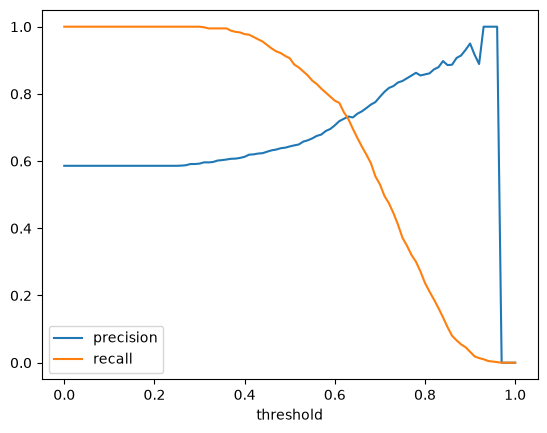

In [35]:
plt.plot(df_pr.threshold, df_pr.precision, label='precision')
plt.plot(df_pr.threshold, df_pr.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

In [36]:
df_pr['f1'] = 2 * df_pr.precision * df_pr.recall / (df_pr.precision + df_pr.recall)

In [37]:
melhor = df_pr.loc[df_pr.f1.idxmax()]
melhor

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

In [38]:
df_pr.loc[df_pr.f1.idxmax(), 'threshold']

np.float64(0.41)

In [40]:
from sklearn.model_selection import KFold

In [41]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    y_tr = df_tr['converted'].values
    y_va = df_va['converted'].values

    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_tr[categoricas + numericas].to_dict(orient='records'))
    X_va = dv.transform(df_va[categoricas + numericas].to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_tr, y_tr)

    y_pred = model.predict_proba(X_va)[:, 1]
    scores.append(roc_auc_score(y_va, y_pred))

print(scores)
print(round(np.std(scores), 3))

[0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
0.007


In [42]:
def treinar_e_avaliar(df_tr, df_va, C):
    y_tr = df_tr['converted'].values
    y_va = df_va['converted'].values

    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_tr[categoricas + numericas].to_dict(orient='records'))
    X_va = dv.transform(df_va[categoricas + numericas].to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_tr, y_tr)

    y_pred = model.predict_proba(X_va)[:, 1]
    return roc_auc_score(y_va, y_pred)

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        scores.append(treinar_e_avaliar(df_tr, df_va, C))

    print(f'C={C}  média={np.mean(scores):.3f}  std={np.std(scores):.3f}')

C=1e-06  média=0.617  std=0.019
C=0.001  média=0.749  std=0.010
C=1  média=0.732  std=0.007
